# Prepoznavanje zdravstvenog stanja pčela sa fotografije
### KORAK 2: Prvi eksperiment (BeeImage) — zašto model sa 97% tačnosti ne radi

Na BeeImage-u su trenirane sve tri arhitekture. Rezultati na test skupu su odlični. Ali ručni test u
aplikaciji je pokazao da model **ne prepoznaje bolest**. Ovaj notebook to dokazuje.

## 1. Uvoz biblioteka

In [1]:
import sys, os, json, ast, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw

# src.evaluate pri importu prebacuje matplotlib u "Agg" (bez prikaza) — zato se
# učitava ovde, pa se prikaz u notebook-u vraća sa %matplotlib inline
import src.evaluate, src.model_checks
%matplotlib inline

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 60)

GRAFICI = ROOT / "grafici"; GRAFICI.mkdir(exist_ok=True)
RUNS = ROOT / "runs"

# Iste boje u svim graficima
BOJA_KLASE = {"zdrava": "#2ecc71", "varoa": "#e74c3c"}
BOJA_MODELA = {"MobileNetV3-Large": "#3498db", "ResNet50": "#9b59b6", "EfficientNetB0": "#f39c12"}
MODELI = ["MobileNetV3-Large", "ResNet50", "EfficientNetB0"]
RUN_ZA = {"MobileNetV3-Large": "varroa_mobilenet_v3_large", "ResNet50": "varroa_resnet50",
          "EfficientNetB0": "varroa_efficientnet_b0"}

def sacuvaj(ime):
    """Čuva trenutni grafik u grafici/<ime>.png (isti grafici idu u prezentaciju)."""
    plt.savefig(GRAFICI / f"{ime}.png", dpi=150, bbox_inches="tight")

def oznaci_stubice(ax, fmt="{:.3f}", rot=0, size=9):
    for p in ax.patches:
        h = p.get_height()
        if np.isfinite(h) and h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h), ha="center",
                        va="bottom", fontsize=size, rotation=rot, xytext=(0, 2), textcoords="offset points")

print("Biblioteke uspešno učitane. Koren projekta:", ROOT)

Biblioteke uspešno učitane. Koren projekta: /Users/medzidjasarovic/Kosnica_IS/KosnicaML


## 2. Rezultati na BeeImage test skupu (3 klase, 776 slika)

In [2]:
bi = []
for p in sorted(RUNS.glob("*_3cls/metrics.json")):
    m = json.loads(p.read_text())
    bi.append({"Model": m["arch_display"], "Tačnost": m["accuracy"], "Preciznost": m["macro_precision"],
               "Odziv": m["macro_recall"], "F1": m["macro_f1"], "Odziv (varoa)": m["varroa_recall"]})
bi = pd.DataFrame(bi).set_index("Model").loc[MODELI]
print("BEEIMAGE — TEST SKUP (nasumična podela)"); print("=" * 50)
bi.round(4)

BEEIMAGE — TEST SKUP (nasumična podela)


,Tačnost,Preciznost,Odziv,F1,Odziv (varoa)
Model,,,,,
MobileNetV3-Large,0.9704,0.9529,0.9767,0.9643,0.9747
ResNet50,0.9716,0.9557,0.9698,0.9625,0.9620
EfficientNetB0,0.9111,0.8701,0.9278,0.8954,0.9241


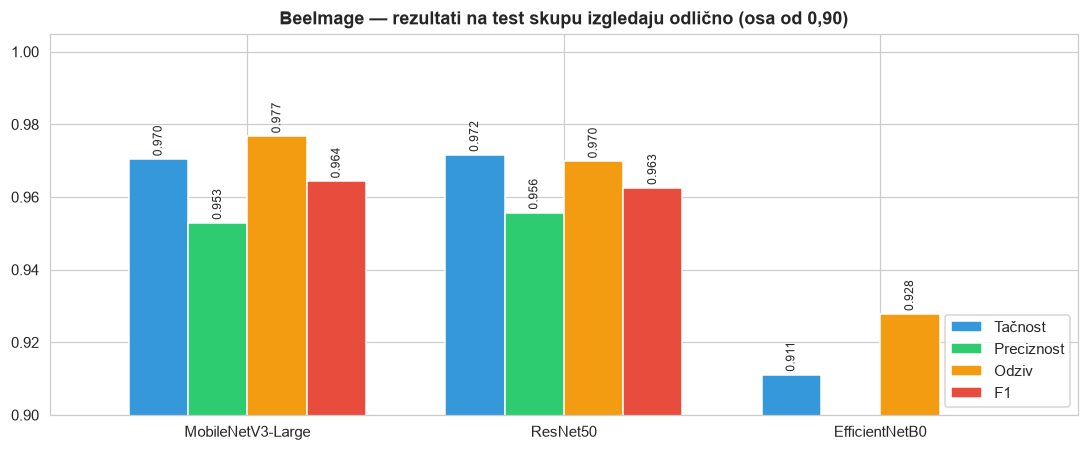

In [3]:
ax = bi[["Tačnost", "Preciznost", "Odziv", "F1"]].plot(kind="bar", figsize=(10, 4.2), rot=0, width=0.75,
                                                      color=["#3498db", "#2ecc71", "#f39c12", "#e74c3c"])
ax.set_ylim(0.9, 1.005); ax.set_title("BeeImage — rezultati na test skupu izgledaju odlično (osa od 0,90)"); ax.set_xlabel("")
oznaci_stubice(ax, "{:.3f}", rot=90, size=8); ax.legend(loc="lower right")
plt.tight_layout(); sacuvaj("02a_beeimage_rezultati"); plt.show()

## 3. Ručni test u aplikaciji

Fotografija pčele na saću sa **dve jasno vidljive grinje**, propuštena kroz BeeImage model
(isti ONNX fajl koji je tada bio u aplikaciji):

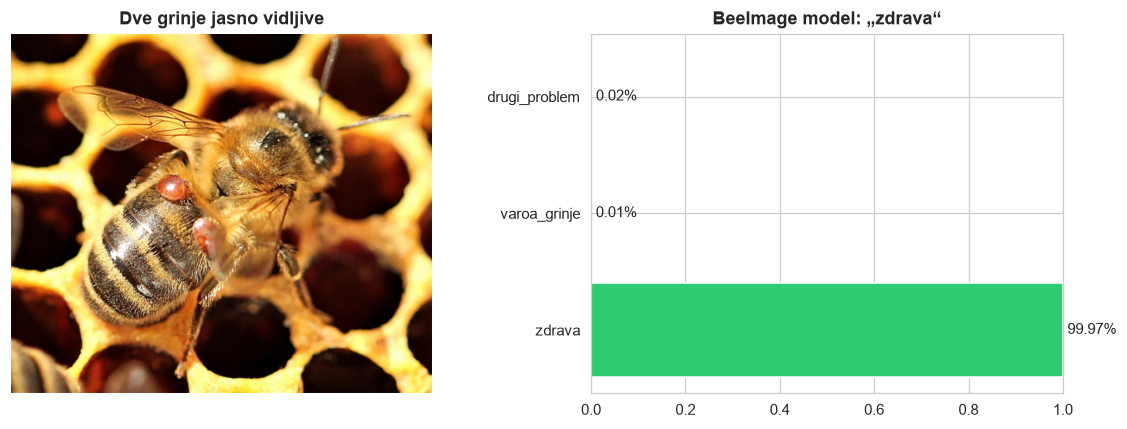

{'label': 'zdrava', 'confidence': 0.9997, 'all_probs': {'zdrava': 0.9997, 'varoa_grinje': 0.0001, 'drugi_problem': 0.0002}, 'model_version': 'bee_health'}


In [4]:
from service.inference import BeeHealthModel
stari = BeeHealthModel(ROOT / "models" / "beeimage" / "mobilenet_v3_large_3cls.onnx")
foto = ROOT / "data" / "field_photos" / "varoa" / "makro_pcela_na_sacu_2_grinje.jpg"
r = stari.predict(foto.read_bytes())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.2, 1]})
axes[0].imshow(Image.open(foto)); axes[0].axis("off"); axes[0].set_title("Dve grinje jasno vidljive")
k = list(r["all_probs"]); v = list(r["all_probs"].values())
axes[1].barh(k, v, color=["#2ecc71", "#e74c3c", "#95a5a6"]); axes[1].set_xlim(0, 1)
for i, x in enumerate(v): axes[1].text(x + 0.01, i, f"{x:.2%}", va="center")
axes[1].set_title("BeeImage model: „zdrava“")
plt.tight_layout(); sacuvaj("02b_beeimage_promasaj"); plt.show()
print(r)

## 4. Test prečice (*shortcut test*)

**Hipoteza:** model je naučio pozadinu snimka, a ne izgled pčele.

**Test:** modelu se daju **samo četiri ugla** slike (25% širine i visine). Pčela je u centru isečka,
pa su u uglovima uglavnom pozadina i podloga. Kad bi model gledao pčelu, iz uglova bi pogađao na
nivou slučaja — **33%** za tri klase.

In [5]:
import io
def png(img):
    b = io.BytesIO(); img.save(b, "PNG"); return b.getvalue()

test = load_split("test", 3) if "load_split" in dir() else None
from src.dataset import load_split
test = load_split("test", 3)
rez = []
for klasa in stari.classes:
    sub = test[test["label"] == klasa]
    cela = uglovi = 0.0
    for path in sub["path"]:
        img = Image.open(path).convert("RGB"); w, h = img.size; qw, qh = w // 4, h // 4
        cela += stari.predict(png(img))["label"] == klasa
        kutije = [(0, 0, qw, qh), (w - qw, 0, w, qh), (0, h - qh, qw, h), (w - qw, h - qh, w, h)]
        uglovi += sum(stari.predict(png(img.crop(b)))["label"] == klasa for b in kutije) / 4
    rez.append({"klasa": klasa, "slika": len(sub), "cela slika": cela / len(sub), "samo uglovi": uglovi / len(sub)})
rez = pd.DataFrame(rez).set_index("klasa"); rez.round(3)

,slika,cela slika,samo uglovi
klasa,,,
zdrava,507,0.964,0.840
varoa_grinje,158,0.975,0.739
drugi_problem,111,0.991,0.108


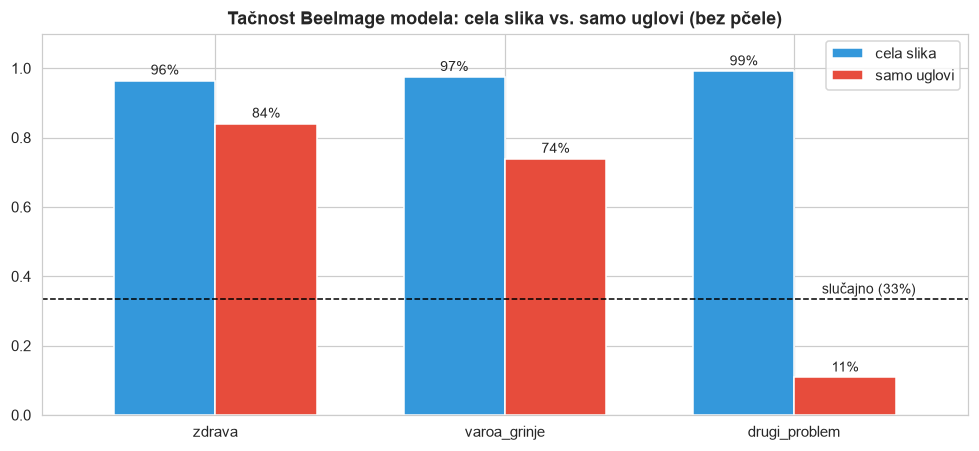

In [6]:
ax = rez[["cela slika", "samo uglovi"]].plot(kind="bar", figsize=(9, 4.2), rot=0, color=["#3498db", "#e74c3c"], width=0.7)
ax.axhline(1 / 3, color="k", ls="--", lw=1); ax.text(2.42, 0.35, "slučajno (33%)", fontsize=9, ha="right")
oznaci_stubice(ax, "{:.0%}"); ax.set_ylim(0, 1.1); ax.set_xlabel("")
ax.set_title("Tačnost BeeImage modela: cela slika vs. samo uglovi (bez pčele)")
plt.tight_layout(); sacuvaj("02c_test_precice"); plt.show()

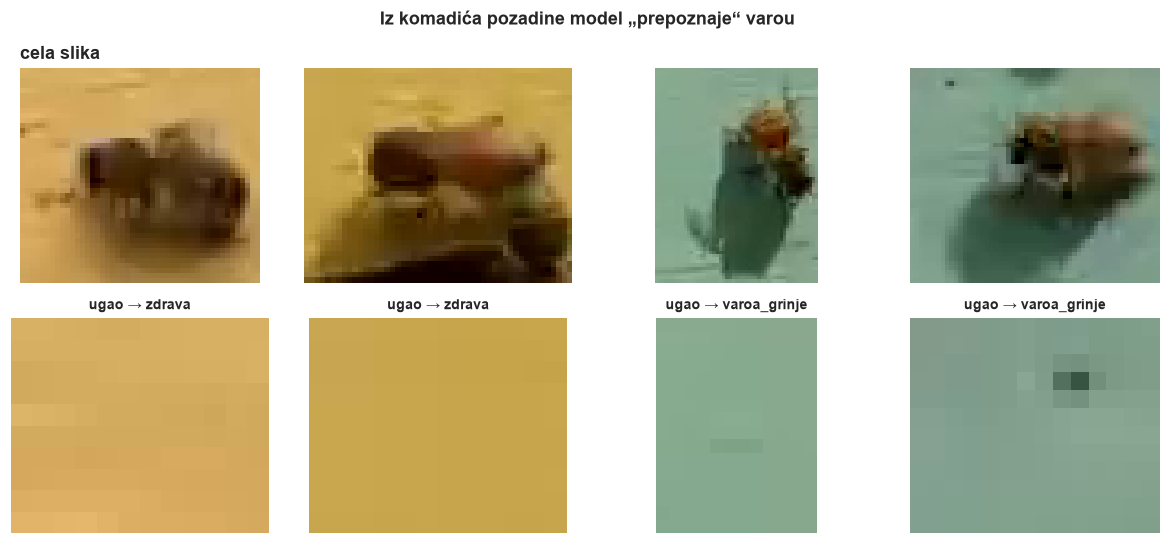

In [7]:
# Kako izgleda ono što model dobija u testu: uglovi slika iz klase varoe
uz = test[test["label"] == "varoa_grinje"].sample(4, random_state=0)
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for c, path in enumerate(uz["path"]):
    img = Image.open(path).convert("RGB"); w, h = img.size
    axes[0, c].imshow(img); axes[0, c].axis("off")
    ugao = img.crop((0, 0, w // 4, h // 4))
    axes[1, c].imshow(ugao); axes[1, c].axis("off")
    axes[1, c].set_title(f"ugao → {stari.predict(png(ugao))['label']}", fontsize=9)
axes[0, 0].set_title("cela slika", loc="left"); fig.suptitle("Iz komadića pozadine model „prepoznaje“ varou", fontweight="bold")
plt.tight_layout(); sacuvaj("02d_uglovi_primeri"); plt.show()

## 5. Zaključak KORAKA 2

Iz komadića pozadine **na kome pčele nema**, model u oko **74%** slučajeva „prepoznaje“ varou.
Tačnost od 97% je tačan broj, ali meri **prepoznavanje snimka**, a ne bolesti. Ova pojava se u
literaturi zove *shortcut learning*.

**Pouke ugrađene u glavni eksperiment:**
1. oznaka **po pčeli**, na osnovu vidljivog obeležja
2. **ista pozadina** za sve klase
3. podela **po snimku** — test sadrži snimke koje model nije video
4. visoka tačnost nije dovoljna — treba **proveriti šta model gleda** (KORAK 5)